<a href="https://colab.research.google.com/github/laurencristine62-arch/fonte-inf-BD/blob/main/Rlpicole.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("sakshisatre/ice-cream-sales-dataset")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'ice-cream-sales-dataset' dataset.
Path to dataset files: /kaggle/input/ice-cream-sales-dataset


In [ ]:
import os
import pandas as pd

# Listar os arquivos dentro do diretório do dataset
files = os.listdir(path)
print('Arquivos no dataset:', files)

# Encontrar o primeiro arquivo CSV para carregar
csv_files = [f for f in files if f.endswith('.csv')]
if csv_files:
    csv_path = os.path.join(path, csv_files[0])
    df = pd.read_csv(csv_path)
    print(f'\nExibindo as primeiras linhas de: {csv_files[0]}')
    display(df.head())
else:
    print('Nenhum arquivo CSV encontrado no diretório.')

Arquivos no dataset: ['Ice Cream.csv']

Exibindo as primeiras linhas de: Ice Cream.csv


,Temperature,Revenue
0,24.6,535
1,26.1,626
2,27.8,661
3,20.6,488
4,11.6,317


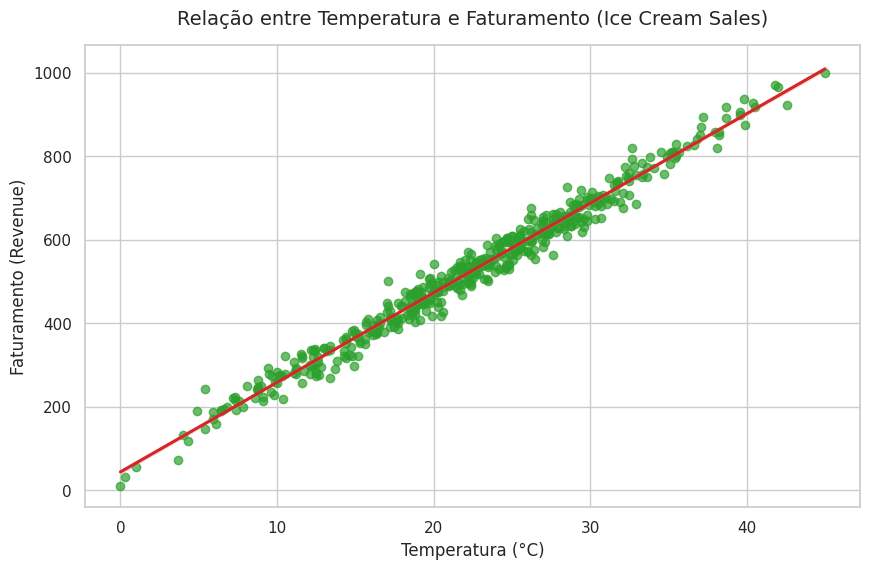

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Configurar o estilo do gráfico
sns.set_theme(style="whitegrid")

# Criar a figura
plt.figure(figsize=(10, 6))

# Criar o gráfico de dispersão com uma linha de tendência (regressão linear)
sns.regplot(data=df, x='Temperature', y='Revenue', scatter_kws={'alpha':0.7, 'color': '#2ca02c'}, line_kws={'color': '#d62728'})

# Configurações de títulos e eixos
plt.title('Relação entre Temperatura e Faturamento (Ice Cream Sales)', fontsize=14, pad=15)
plt.xlabel('Temperatura (°C)', fontsize=12)
plt.ylabel('Faturamento (Revenue)', fontsize=12)

# Exibir o gráfico
plt.show()

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn import metrics

# 1. Definindo as variáveis preditora (X) e alvo (y)
X = df[['Temperature']]
y = df['Revenue']

# 2. Dividindo o dataset em treino (80%) e teste (20%)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 3. Inicializando e ajustando o modelo de Regressão Linear
modelo = LinearRegression()
modelo.fit(X_train, y_train)

# 4. Realizando previsões
y_pred = modelo.predict(X_test)

# 5. Calculando métricas de avaliação
r2 = metrics.r2_score(y_test, y_pred)
mae = metrics.mean_absolute_error(y_test, y_pred)
mse = metrics.mean_squared_error(y_test, y_pred)

print("=== Modelo de Regressão Linear Simples ===")
print(f"Inclinação (Coeficiente): {modelo.coef_[0]:.4f}")
print(f"Intercepto: {modelo.intercept_:.4f}")
print(f"R² (Coeficiente de Determinação): {r2:.4f}")
print(f"Erro Médio Absoluto (MAE): {mae:.4f}")
print(f"Erro Quadrático Médio (MSE): {mse:.4f}")

=== Modelo de Regressão Linear Simples ===
Inclinação (Coeficiente): 21.3840
Intercepto: 46.1783
R² (Coeficiente de Determinação): 0.9772
Erro Médio Absoluto (MAE): 19.1957
Erro Quadrático Médio (MSE): 652.4938
